<a href="https://colab.research.google.com/github/PaigeLaybourn-Morris/Redington-Immunisation/blob/main/RedingtonImmunisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

REDINGTON IMMUNISATION RESULTS
--------------------------------
Asset payment at time 1 (a): 47.61905
Asset payment at time 3 (b): 52.50000
Asset PV at 5%: 90.70294785
Liability PV at 5%: 90.70294785
Surplus at 5%: 0.00000000
First derivative at 5%: -0.00000000
Second derivative at 5%: 82.27025


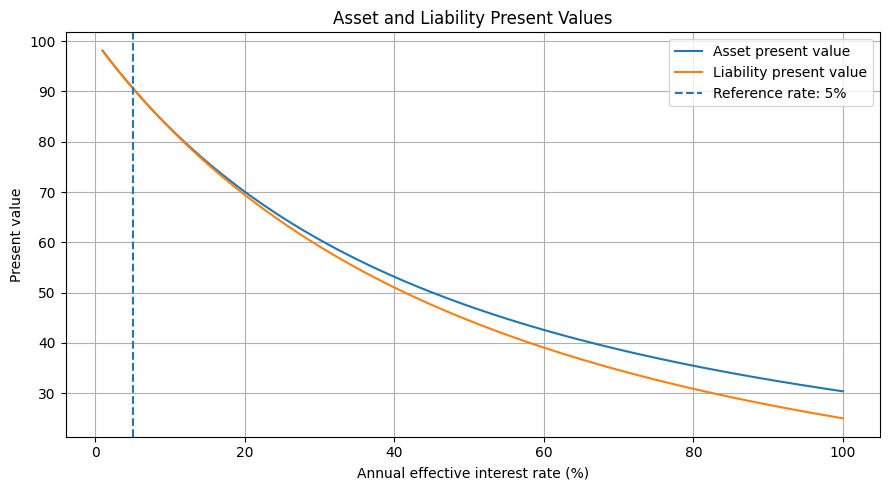

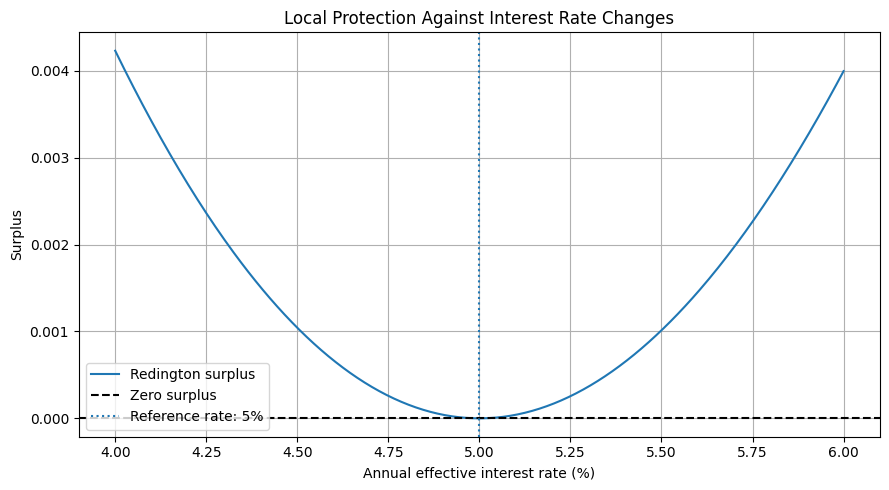

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Reference rate and asset cash flows
# ==========================================

i0 = 0.05
b = 52.5
a = b / (1 + i0)**2

# ==========================================
# 2. Present-value functions
# ==========================================

def asset_value(i):
    return a / (1 + i) + b / (1 + i)**3

def liability_value(i):
    return 100 / (1 + i)**2

def surplus(i):
    return asset_value(i) - liability_value(i)

# ==========================================
# 3. Derivatives of the surplus
# ==========================================

def surplus_first_derivative(i):
    return (
        -a / (1 + i)**2
        - 3*b / (1 + i)**4
        + 200 / (1 + i)**3
    )

def surplus_second_derivative(i):
    return (
        2*a / (1 + i)**3
        + 12*b / (1 + i)**5
        - 600 / (1 + i)**4
    )

# ==========================================
# 4. Verify the Redington conditions
# ==========================================

print("REDINGTON IMMUNISATION RESULTS")
print("--------------------------------")
print(f"Asset payment at time 1 (a): {a:.5f}")
print(f"Asset payment at time 3 (b): {b:.5f}")
print(f"Asset PV at 5%: {asset_value(i0):.8f}")
print(f"Liability PV at 5%: {liability_value(i0):.8f}")
print(f"Surplus at 5%: {surplus(i0):.8f}")
print(f"First derivative at 5%: "
      f"{surplus_first_derivative(i0):.8f}")
print(f"Second derivative at 5%: "
      f"{surplus_second_derivative(i0):.5f}")

# ==========================================
# 5. Graph 1: Curved present-value functions
# ==========================================

# Use a wider range to make the curvature visible
rates_wide = np.linspace(0.01, 1.00, 500)

plt.figure(figsize=(9, 5))

plt.plot(
    rates_wide * 100,
    asset_value(rates_wide),
    label="Asset present value"
)

plt.plot(
    rates_wide * 100,
    liability_value(rates_wide),
    label="Liability present value"
)

plt.axvline(
    5,
    linestyle="--",
    label="Reference rate: 5%"
)

plt.xlabel("Annual effective interest rate (%)")
plt.ylabel("Present value")
plt.title("Asset and Liability Present Values")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ==========================================
# 6. Graph 2: Surplus near the reference rate
# ==========================================

rates_zoom = np.linspace(0.04, 0.06, 401)

plt.figure(figsize=(9, 5))

plt.plot(
    rates_zoom * 100,
    surplus(rates_zoom),
    label="Redington surplus"
)

plt.axhline(
    0,
    linestyle="--",
    color="black",
    label="Zero surplus"
)

plt.axvline(
    5,
    linestyle=":",
    label="Reference rate: 5%"
)

plt.xlabel("Annual effective interest rate (%)")
plt.ylabel("Surplus")
plt.title("Local Protection Against Interest Rate Changes")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


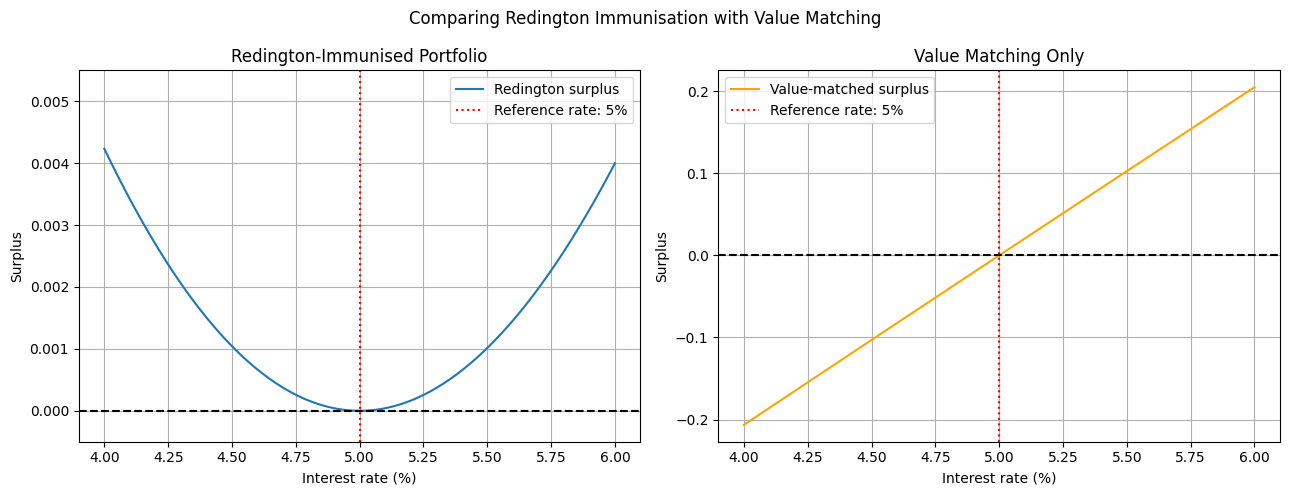

In [5]:

# Alternative portfolio: matches present value only
b_alt = 40
a_alt = (105 - b_alt) / (1.05**2)

def alternative_surplus(i):
    assets = a_alt / (1 + i) + b_alt / (1 + i)**3
    liabilities = 100 / (1 + i)**2
    return assets - liabilities

# Interest rates between 4% and 6%
rates_zoom = np.linspace(0.04, 0.06, 401)

# Calculate the Redington surplus for setting the vertical scale
redington_values = surplus(rates_zoom)

# Create two graphs with independent vertical scales
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Redington-immunised portfolio
axes[0].plot(
    rates_zoom * 100,
    redington_values,
    label="Redington surplus"
)

axes[0].axhline(0, linestyle="--", color="black")
axes[0].axvline(5, linestyle=":", color="red",
                label="Reference rate: 5%")

axes[0].set_ylim(-0.0005, 0.0055)
axes[0].set_xlabel("Interest rate (%)")
axes[0].set_ylabel("Surplus")
axes[0].set_title("Redington-Immunised Portfolio")
axes[0].legend()
axes[0].grid(True)

# Graph 2: Portfolio matching value only
axes[1].plot(
    rates_zoom * 100,
    alternative_surplus(rates_zoom),
    color="orange",
    label="Value-matched surplus"
)

axes[1].axhline(0, linestyle="--", color="black")
axes[1].axvline(5, linestyle=":", color="red",
                label="Reference rate: 5%")

axes[1].set_xlabel("Interest rate (%)")
axes[1].set_ylabel("Surplus")
axes[1].set_title("Value Matching Only")
axes[1].legend()
axes[1].grid(True)

fig.suptitle("Comparing Redington Immunisation with Value Matching")
plt.tight_layout()
plt.show()